In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
dfc=pd.read_csv('calories.csv')
dfe=pd.read_csv('exercise.csv')

In [3]:
dfc.head(5)

,User_ID,Calories
0,14733363,231.0
1,14861698,66.0
2,11179863,26.0
3,16180408,71.0
4,17771927,35.0


In [4]:
dfe.head(5)

,User_ID,Gender,Age,Height,Weight,Duration,Heart_Rate,Body_Temp
0,14733363,male,68,190.0,94.0,29.0,105.0,40.8
1,14861698,female,20,166.0,60.0,14.0,94.0,40.3
2,11179863,male,69,179.0,79.0,5.0,88.0,38.7
3,16180408,female,34,179.0,71.0,13.0,100.0,40.5
4,17771927,female,27,154.0,58.0,10.0,81.0,39.8


In [5]:
df=pd.merge(dfc,dfe,on='User_ID')

In [6]:
df.head(5)

,User_ID,Calories,Gender,Age,Height,Weight,Duration,Heart_Rate,Body_Temp
0,14733363,231.0,male,68,190.0,94.0,29.0,105.0,40.8
1,14861698,66.0,female,20,166.0,60.0,14.0,94.0,40.3
2,11179863,26.0,male,69,179.0,79.0,5.0,88.0,38.7
3,16180408,71.0,female,34,179.0,71.0,13.0,100.0,40.5
4,17771927,35.0,female,27,154.0,58.0,10.0,81.0,39.8


In [7]:
df.shape

(15000, 9)

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   User_ID     15000 non-null  int64  
 1   Calories    15000 non-null  float64
 2   Gender      15000 non-null  str    
 3   Age         15000 non-null  int64  
 4   Height      15000 non-null  float64
 5   Weight      15000 non-null  float64
 6   Duration    15000 non-null  float64
 7   Heart_Rate  15000 non-null  float64
 8   Body_Temp   15000 non-null  float64
dtypes: float64(6), int64(2), str(1)
memory usage: 1.1 MB


In [9]:
df=df.drop(['User_ID'],axis=1)

In [10]:
df.head(3)

,Calories,Gender,Age,Height,Weight,Duration,Heart_Rate,Body_Temp
0,231.0,male,68,190.0,94.0,29.0,105.0,40.8
1,66.0,female,20,166.0,60.0,14.0,94.0,40.3
2,26.0,male,69,179.0,79.0,5.0,88.0,38.7


In [11]:
df.isnull().sum()

Calories      0
Gender        0
Age           0
Height        0
Weight        0
Duration      0
Heart_Rate    0
Body_Temp     0
dtype: int64

In [12]:
df.describe()

,Calories,Age,Height,Weight,Duration,Heart_Rate,Body_Temp
count,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000
mean,89.539533,42.789800,174.465133,74.966867,15.530600,95.518533,40.025453
std,62.456978,16.980264,14.258114,15.035657,8.319203,9.583328,0.779230
min,1.000000,20.000000,123.000000,36.000000,1.000000,67.000000,37.100000
25%,35.000000,28.000000,164.000000,63.000000,8.000000,88.000000,39.600000
50%,79.000000,39.000000,175.000000,74.000000,16.000000,96.000000,40.200000
75%,138.000000,56.000000,185.000000,87.000000,23.000000,103.000000,40.600000
max,314.000000,79.000000,222.000000,132.000000,30.000000,128.000000,41.500000


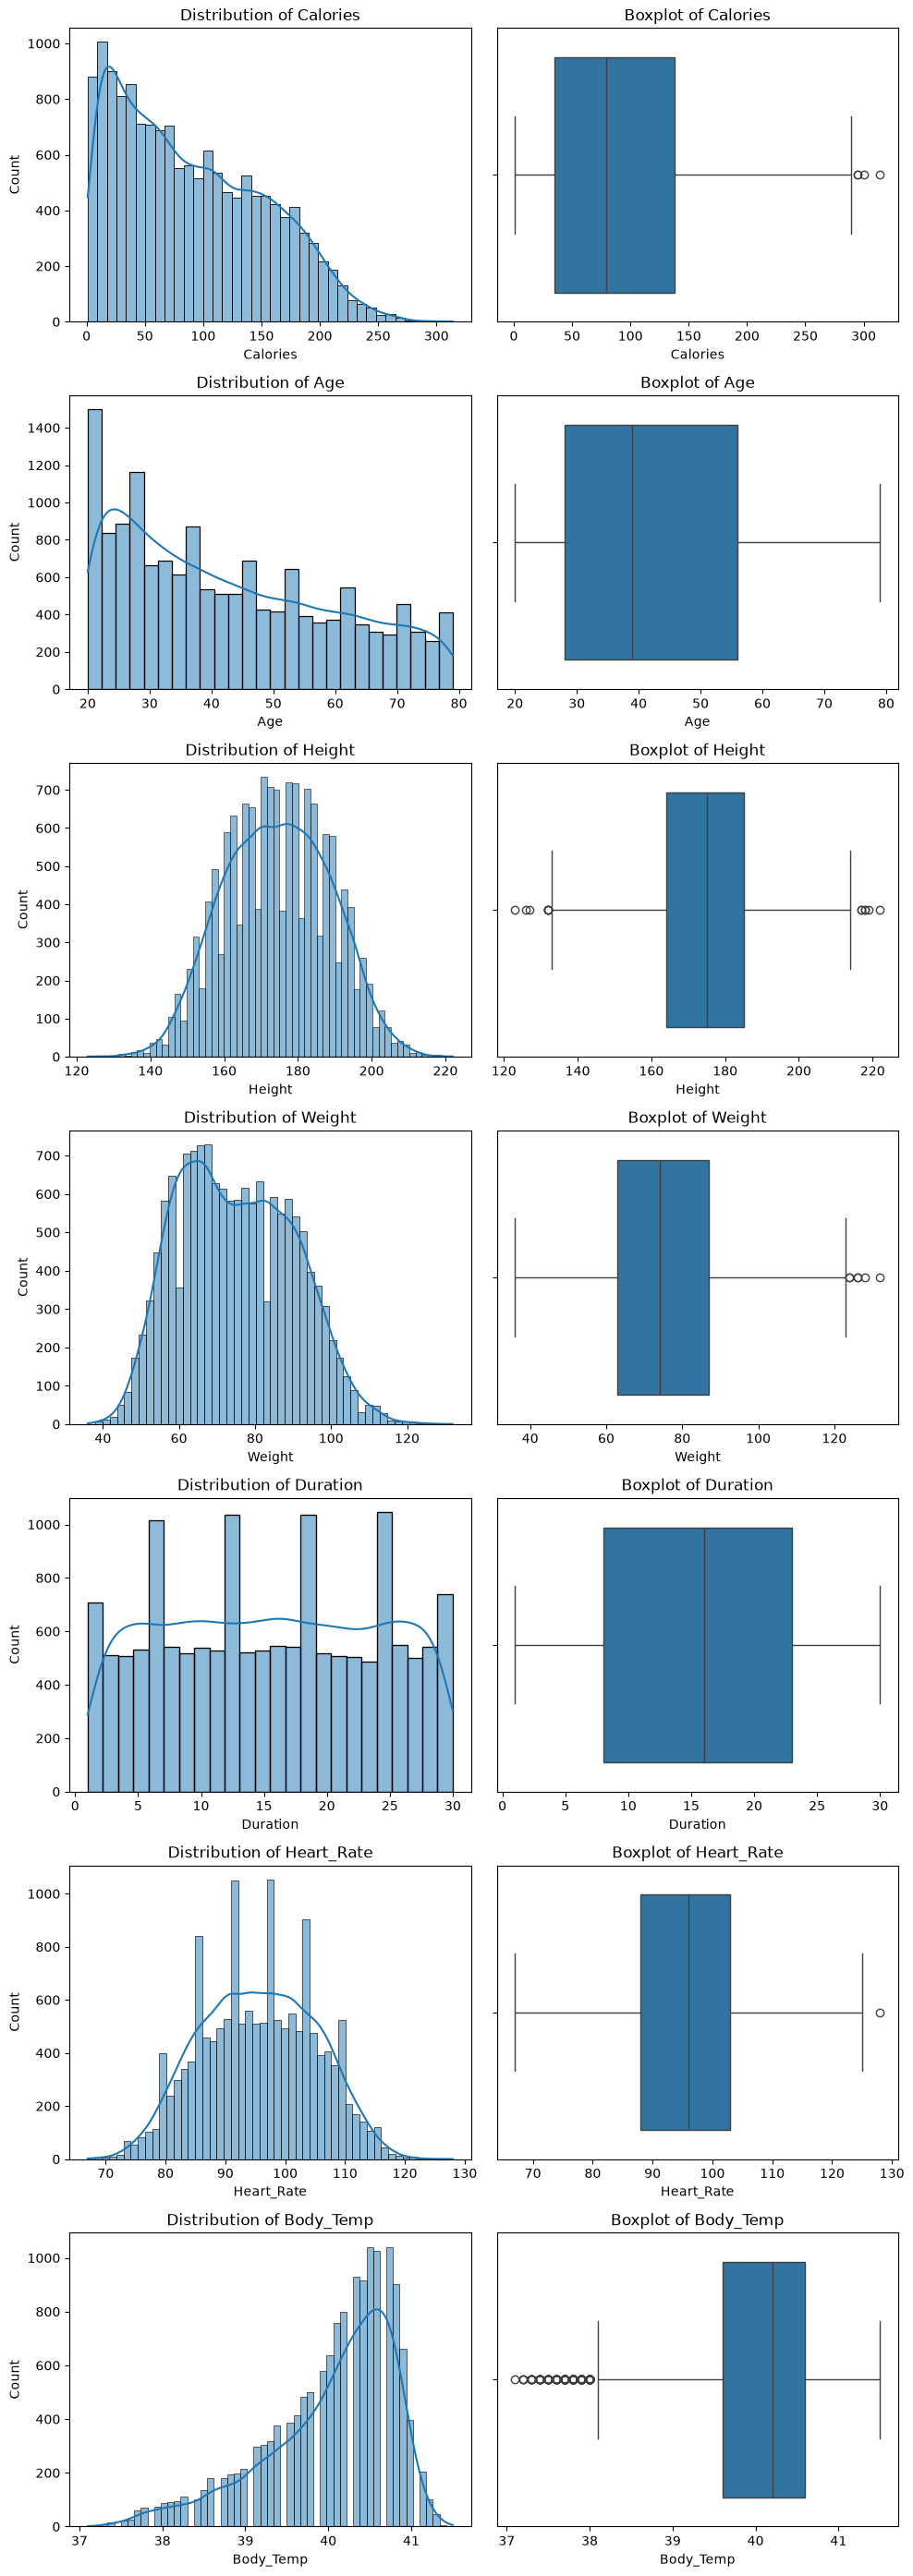

In [13]:


columns = [
    "Calories", "Age", "Height", "Weight",
    "Duration", "Heart_Rate", "Body_Temp"
]

fig, ax = plt.subplots(7, 2, figsize=(10, 28))

for i, column in enumerate(columns):
    sns.histplot(df[column], ax=ax[i, 0], kde=True)
    ax[i, 0].set_title(f"Distribution of {column}")

    sns.boxplot(x=df[column], ax=ax[i, 1])
    ax[i, 1].set_title(f"Boxplot of {column}")

plt.tight_layout()
plt.show()

In [18]:
for i in columns:
    q1=df[i].quantile(0.25)
    q3=df[i].quantile(0.75)
    iqr=q3-q1
    low=q1-1.5*iqr
    high=q3+1.5*iqr
    df=df[df[i].between(low,high)]

In [19]:
df['Age']=np.log1p(df['Age'])

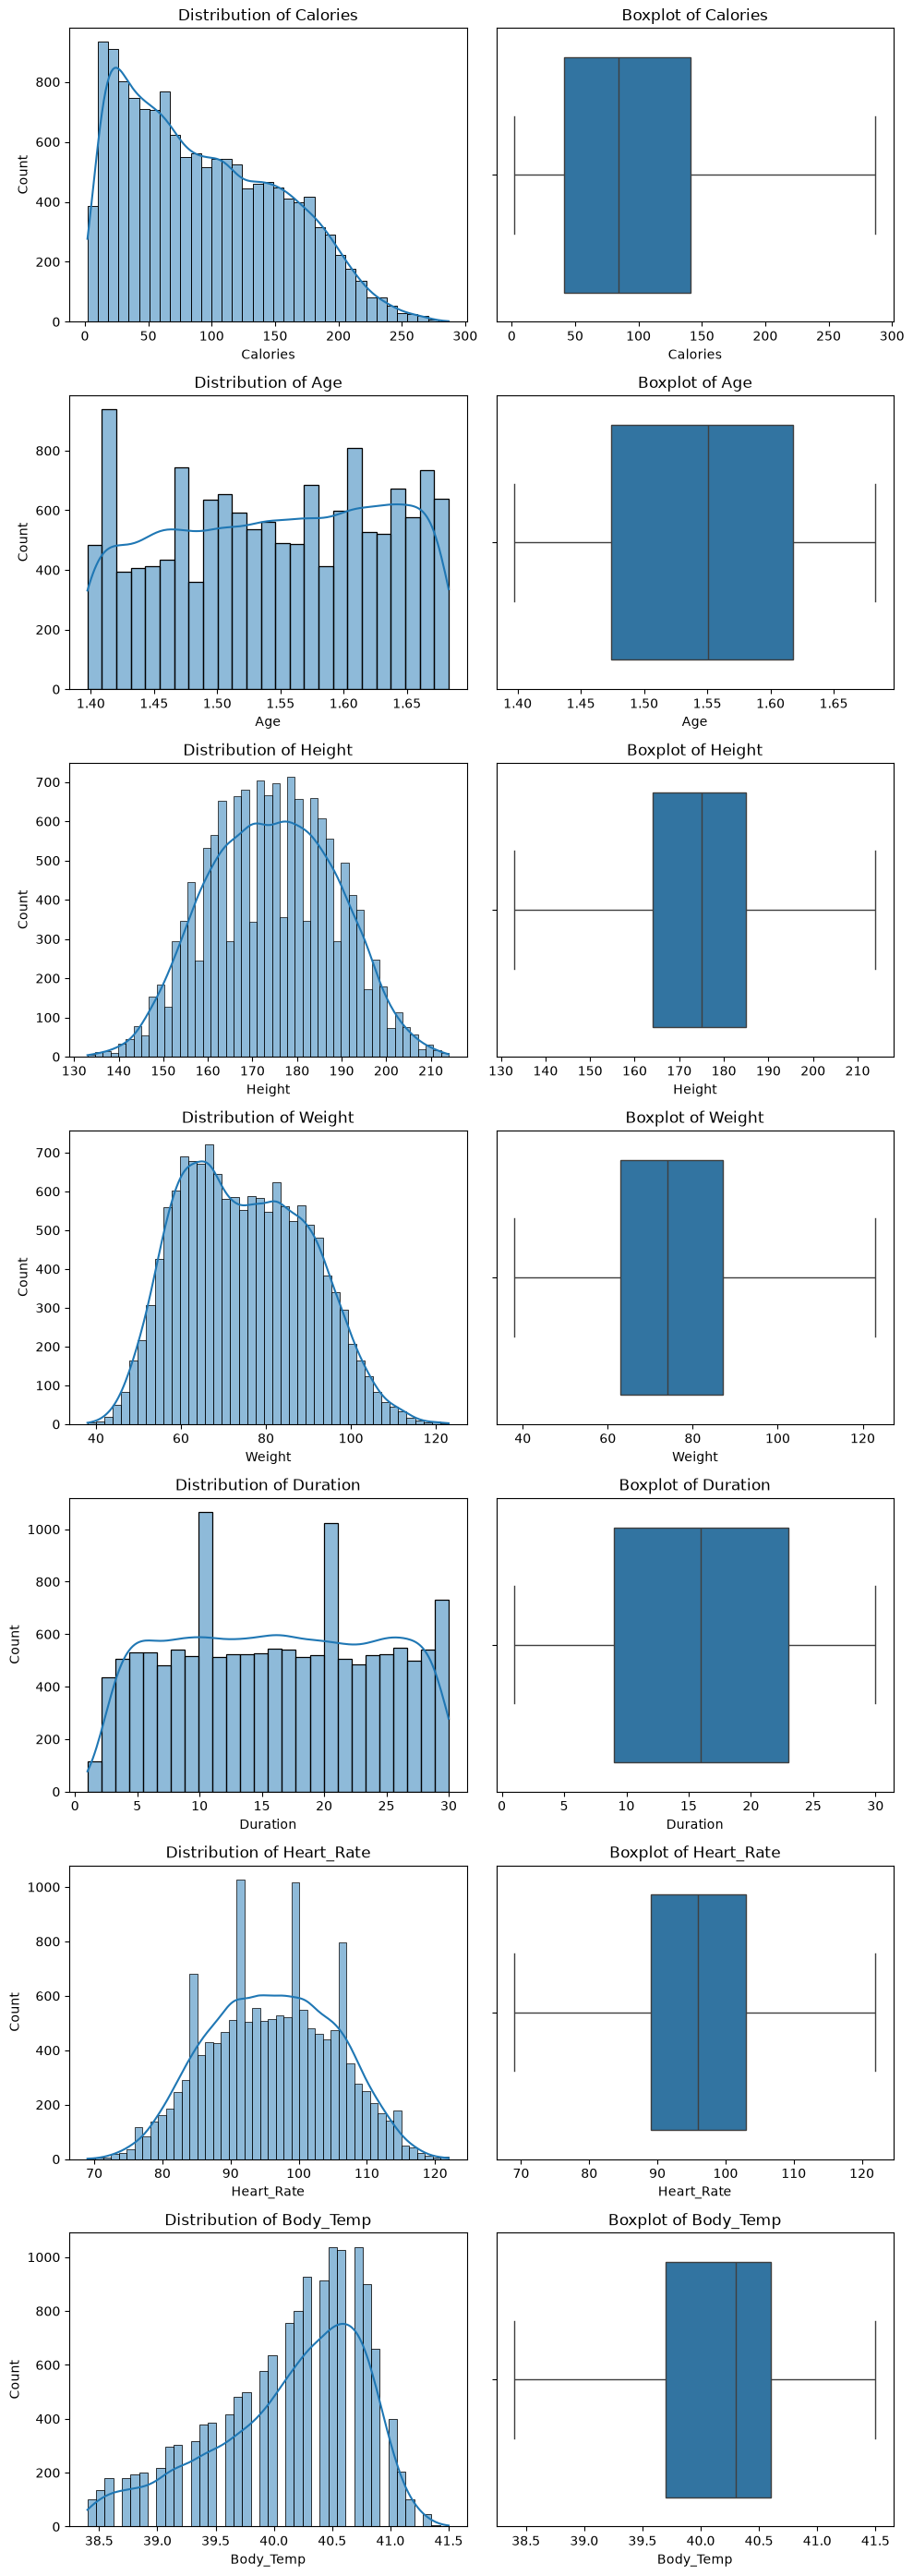

In [20]:


fig, ax = plt.subplots(7, 2, figsize=(10, 28))

for i, column in enumerate(columns):
    sns.histplot(df[column], ax=ax[i, 0], kde=True)
    ax[i, 0].set_title(f"Distribution of {column}")

    sns.boxplot(x=df[column], ax=ax[i, 1])
    ax[i, 1].set_title(f"Boxplot of {column}")

plt.tight_layout()
plt.show()

In [21]:
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

In [22]:
df.head(3)

,Calories,Gender,Age,Height,Weight,Duration,Heart_Rate,Body_Temp
0,231.0,male,1.655196,190.0,94.0,29.0,105.0,40.8
1,66.0,female,1.397363,166.0,60.0,14.0,94.0,40.3
2,26.0,male,1.657941,179.0,79.0,5.0,88.0,38.7


In [23]:
df=pd.get_dummies(df, columns=['Gender'],drop_first=True)


In [24]:
df['Gender_male']=df['Gender_male'].astype('int')

<Axes: >

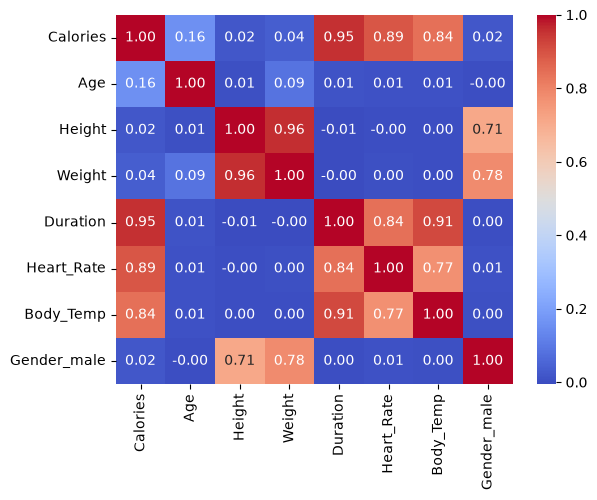

In [25]:
sns.heatmap(df.corr(),annot=True,fmt='.2f',cmap='coolwarm')

#I dont see any strong relation of age with calories or any other column, so i am gonna drop it if the model doesnt show expected result

In [26]:
x=df.drop('Calories',axis=1)
y=df['Calories']

In [27]:
xtrain, xtest, ytrain, ytest = train_test_split(x,y,test_size=0.2,random_state=42)

In [28]:
sc=StandardScaler()
xtrain=sc.fit_transform(xtrain)
xtest=sc.transform(xtest)

In [31]:
#Model Building

In [37]:
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.svm import SVR
from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV

In [39]:

models_and_grids = {
    "LinearRegression": (
        LinearRegression(),
        {}
    ),
    "Ridge": (
        Ridge(),
        {"alpha": [0.1, 1, 10, 100]}
    ),
    "Lasso": (
        Lasso(max_iter=10000),
        {"alpha": [0.001, 0.01, 0.1, 1, 10]}
    ),
    "DecisionTree": (
        DecisionTreeRegressor(random_state=42),
        {"max_depth": [None, 5, 10, 20],
         "min_samples_split": [2, 5, 10]}
    ),
    "SVR": (
        SVR(),
        {"C": [0.1, 1, 10],
         "epsilon": [0.01, 0.1, 0.2],
         "kernel": ["rbf"]}
    ),
    "XGBoost": (
        XGBRegressor(random_state=42, objective="reg:squarederror"),
        {"n_estimators": [100, 300],
         "max_depth": [3, 6],
         "learning_rate": [0.03, 0.1]}
    ),
}

results = []
searches = {}

for name, (estimator, param_grid) in models_and_grids.items():
    search = GridSearchCV(
        estimator,
        param_grid,
        cv=5,
        scoring="neg_root_mean_squared_error",
        n_jobs=-1
    )
    search.fit(xtrain,ytrain)
    searches[name] = search
    results.append({
        "model": name,
        "CV_RMSE": -search.best_score_,
        "best_params": search.best_params_
    })

results_df = pd.DataFrame(results).sort_values("CV_RMSE")
results_df

/opt/anaconda3/envs/ml_env/lib/python3.11/site-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


,model,CV_RMSE,best_params
4,SVR,1.527744,"{'C': 10, 'epsilon': 0.01, 'kernel': 'rbf'}"
5,XGBoost,1.648798,"{'learning_rate': 0.1, 'max_depth': 6, 'n_esti..."
3,DecisionTree,5.633735,"{'max_depth': None, 'min_samples_split': 5}"
0,LinearRegression,11.397542,{}
1,Ridge,11.397542,{'alpha': 0.1}
2,Lasso,11.397551,{'alpha': 0.001}


In [41]:
from sklearn.model_selection import GridSearchCV
from sklearn.svm import SVR
from xgboost import XGBRegressor

param_grids = {
    "SVR": {
        "C": [10, 50],
        "epsilon": [0.01, 0.1],
        "gamma": ["scale", 0.1],
        "kernel": ["rbf"],
    },
    "XGBoost": {
        "n_estimators": [200, 400],
        "max_depth": [3, 6],
        "learning_rate": [0.05, 0.1],
        "min_child_weight": [1],
        "subsample": [0.8],
        "colsample_bytree": [0.8],
    },
}

models = {
    "SVR": SVR(),
    "XGBoost": XGBRegressor(
        objective="reg:squarederror",
        random_state=42,
        n_jobs=1
    ),
}

searches = {}

for name, model in models.items():
    search = GridSearchCV(
        estimator=model,
        param_grid=param_grids[name],
        scoring="neg_root_mean_squared_error",
        cv=3,  # 3 folds instead of 5
        n_jobs=-1,
        verbose=1,
    )
    search.fit(xtrain, ytrain)
    searches[name] = search
    print(f"{name} best CV RMSE: {-search.best_score_:.4f}")
    print(f"{name} best parameters: {search.best_params_}")

Fitting 3 folds for each of 8 candidates, totalling 24 fits
SVR best CV RMSE: 0.6214
SVR best parameters: {'C': 50, 'epsilon': 0.01, 'gamma': 0.1, 'kernel': 'rbf'}
Fitting 3 folds for each of 8 candidates, totalling 24 fits
XGBoost best CV RMSE: 1.6001
XGBoost best parameters: {'colsample_bytree': 0.8, 'learning_rate': 0.05, 'max_depth': 6, 'min_child_weight': 1, 'n_estimators': 400, 'subsample': 0.8}


In [42]:
from sklearn.model_selection import GridSearchCV
from sklearn.svm import SVR

param_grid = {
    "C": [30, 50, 75],
    "epsilon": [0.005, 0.01, 0.02],
    "gamma": [0.05, 0.1, 0.2],
}

search = GridSearchCV(
    SVR(kernel="rbf"),
    param_grid,
    scoring="neg_root_mean_squared_error",
    cv=3,
    n_jobs=-1,
    verbose=1,
)

search.fit(xtrain, ytrain)

print(f"Best CV RMSE: {-search.best_score_:.4f}")
print("Best parameters:", search.best_params_)

Fitting 3 folds for each of 27 candidates, totalling 81 fits
Best CV RMSE: 0.5195
Best parameters: {'C': 75, 'epsilon': 0.02, 'gamma': 0.05}


In [43]:
svr_model = SVR(
    kernel="rbf",
    C=75,
    epsilon=0.02,
    gamma=0.05
)

svr_model.fit(xtrain, ytrain)
predictions = svr_model.predict(xtest)
r2 = r2_score(ytest, predictions)
print(f"R-squared on test set: {r2:.4f}")

R-squared on test set: 0.9999
